# How Experiments Fool You: Power, Peeking, and Multiple Testing

A simulation study of common A/B test pitfalls, using one running example.

**Example question:** Does a redesigned checkout button raise the purchase conversion rate?

**Important:** the data in this notebook is **simulated** so the true effect is known and the methods can be checked against it. It is a demonstration of experiment design and analysis, not a real business result.

What this notebook covers:
1. Planning: sample size from a power calculation, before looking at any data
2. Sanity check: sample ratio mismatch (SRM)
3. Analysis: two-proportion z-test, confidence interval, and effect size
4. Verifying the power calculation by simulation
5. Why peeking at results early inflates false positives
6. Why testing many segments produces false "wins"

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Plan the experiment before collecting data

I fix the design up front so the sample size is not chosen after seeing results.

- Baseline conversion (control): 10.0%
- Minimum detectable effect (MDE): +1.5 percentage points (10.0% to 11.5%), the smallest lift worth acting on
- Significance level alpha = 0.05 (two-sided), power = 0.80

The per-group sample size for two proportions is

$$n = \frac{\left(z_{1-\alpha/2}\sqrt{2\bar p\bar q} + z_{1-\beta}\sqrt{p_1q_1 + p_2q_2}\right)^2}{(p_2 - p_1)^2}$$

In [2]:
def sample_size_per_group(p1, p2, alpha=0.05, power=0.80):
    z_a = stats.norm.ppf(1 - alpha / 2)
    z_b = stats.norm.ppf(power)
    p_bar = (p1 + p2) / 2
    num = (z_a * np.sqrt(2 * p_bar * (1 - p_bar)) + z_b * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
    return int(np.ceil(num / (p2 - p1) ** 2))

P_CONTROL, MDE = 0.10, 0.015
P_TREAT = P_CONTROL + MDE
N = sample_size_per_group(P_CONTROL, P_TREAT)
print(f"Required sample size: {N:,} users per group ({2*N:,} total)")

Required sample size: 6,693 users per group (13,386 total)


## 2. Run the (simulated) experiment

Users are randomly assigned to control or treatment. In this simulation the true treatment rate equals the MDE, so a correct analysis should usually detect it, but not always: power is 80%, not 100%.

In [3]:
assign = rng.integers(0, 2, size=2 * N)               # 0 = control, 1 = treatment
true_rate = np.where(assign == 1, P_TREAT, P_CONTROL)
converted = rng.random(2 * N) < true_rate
df = pd.DataFrame({"group": np.where(assign == 1, "treatment", "control"), "converted": converted.astype(int)})

summary = df.groupby("group")["converted"].agg(users="count", conversions="sum", rate="mean")
summary

,users,conversions,rate
group,,,
control,6759,665,0.098387
treatment,6627,731,0.110306


## 3. Sanity check: sample ratio mismatch (SRM)

Before trusting any result, check that the groups are the size randomization should have produced. A significant imbalance usually means a bug in assignment or logging, and the results cannot be trusted. A strict threshold (p < 0.001) is common because this check runs on every experiment.

In [4]:
counts = summary["users"].values
chi2, p_srm = stats.chisquare(counts, f_exp=[counts.sum() / 2] * 2)
print(f"Group sizes: {counts[0]:,} vs {counts[1]:,}   chi-square = {chi2:.2f}, p = {p_srm:.3f}")
print("SRM check:", "PASS (no evidence of mismatch)" if p_srm > 0.001 else "FAIL (investigate before analyzing)")

Group sizes: 6,759 vs 6,627   chi-square = 1.30, p = 0.254
SRM check: PASS (no evidence of mismatch)


## 4. Analysis: test, confidence interval, effect size

A p-value alone says only whether the data are surprising under "no difference." The decision needs the **size** of the difference and how **uncertain** it is, so I report all three:

- Two-proportion z-test (pooled variance under H0)
- 95% confidence interval for the absolute difference (unpooled standard error)
- Relative lift and Cohen's h as effect sizes

In [5]:
def analyze(x_c, n_c, x_t, n_t, alpha=0.05):
    p_c, p_t = x_c / n_c, x_t / n_t
    diff = p_t - p_c
    # z-test with pooled variance (H0: no difference)
    p_pool = (x_c + x_t) / (n_c + n_t)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_c + 1 / n_t))
    z = diff / se_pool
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    # CI for the difference (unpooled)
    se = np.sqrt(p_c * (1 - p_c) / n_c + p_t * (1 - p_t) / n_t)
    zc = stats.norm.ppf(1 - alpha / 2)
    lo, hi = diff - zc * se, diff + zc * se
    # effect sizes
    cohens_h = 2 * np.arcsin(np.sqrt(p_t)) - 2 * np.arcsin(np.sqrt(p_c))
    return dict(p_control=p_c, p_treatment=p_t, diff=diff, ci_low=lo, ci_high=hi,
                rel_lift=diff / p_c, z=z, p_value=p_value, cohens_h=cohens_h)

g = df.groupby("group")["converted"].agg(["sum", "count"])
res = analyze(g.loc["control", "sum"], g.loc["control", "count"], g.loc["treatment", "sum"], g.loc["treatment", "count"])

print(f"Control:   {res['p_control']:.2%}")
print(f"Treatment: {res['p_treatment']:.2%}")
print(f"Absolute difference: {res['diff']*100:+.2f} pp  (95% CI {res['ci_low']*100:+.2f} to {res['ci_high']*100:+.2f} pp)")
print(f"Relative lift: {res['rel_lift']:+.1%}")
print(f"z = {res['z']:.2f}, p = {res['p_value']:.4f}, Cohen's h = {res['cohens_h']:.3f}")

Control:   9.84%
Treatment: 11.03%
Absolute difference: +1.19 pp  (95% CI +0.16 to +2.23 pp)
Relative lift: +12.1%
z = 2.26, p = 0.0241, Cohen's h = 0.039


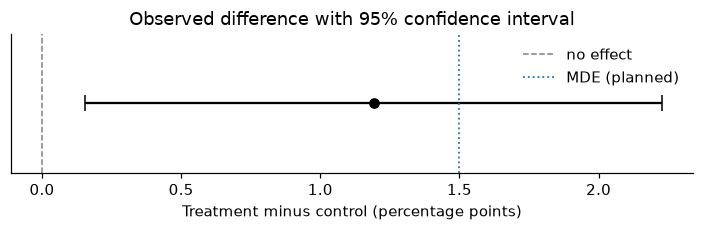

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 2.2))
ax.errorbar(res["diff"] * 100, 0, xerr=[[res["diff"] * 100 - res["ci_low"] * 100], [res["ci_high"] * 100 - res["diff"] * 100]],
            fmt="o", color="black", capsize=5)
ax.axvline(0, color="grey", ls="--", lw=1, label="no effect")
ax.axvline(MDE * 100, color="tab:blue", ls=":", lw=1.2, label="MDE (planned)")
ax.set_yticks([]); ax.set_xlabel("Treatment minus control (percentage points)")
ax.set_title("Observed difference with 95% confidence interval"); ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

## 5. Does the power calculation hold up? (simulation check)

If the design is right, then:
- when the true effect equals the MDE, about **80%** of repeated experiments should reach p < 0.05
- when there is **no** true effect, about **5%** should (the false-positive rate)

I repeat the experiment 5,000 times in each case to check.

In [7]:
def simulate_rejection_rate(p_c, p_t, n, reps=5000, alpha=0.05):
    x_c = rng.binomial(n, p_c, size=reps)
    x_t = rng.binomial(n, p_t, size=reps)
    p_pool = (x_c + x_t) / (2 * n)
    se = np.sqrt(p_pool * (1 - p_pool) * (2 / n))
    z = (x_t / n - x_c / n) / se
    return np.mean(np.abs(z) > stats.norm.ppf(1 - alpha / 2))

power_sim = simulate_rejection_rate(P_CONTROL, P_TREAT, N)
alpha_sim = simulate_rejection_rate(P_CONTROL, P_CONTROL, N)
print(f"Empirical power at true effect = MDE:  {power_sim:.1%}  (target 80%)")
print(f"Empirical false-positive rate (A/A):   {alpha_sim:.1%}  (target 5%)")

Empirical power at true effect = MDE:  79.3%  (target 80%)
Empirical false-positive rate (A/A):   5.1%  (target 5%)


## 6. Peeking: why stopping at the first "significant" result is a mistake

A common mistake is checking the test repeatedly and stopping the first time p < 0.05. Every extra look is another chance for noise to cross the line. Here there is **no true effect** (an A/A test), and I check the result at 10 evenly spaced points.

In [8]:
reps, looks = 4000, 10
n_per_look = N // looks
# per-look conversions for each arm, accumulated over time
inc_c = rng.binomial(n_per_look, P_CONTROL, size=(reps, looks)).cumsum(axis=1)
inc_t = rng.binomial(n_per_look, P_CONTROL, size=(reps, looks)).cumsum(axis=1)   # same rate: no real effect
n_seen = n_per_look * np.arange(1, looks + 1)

p_pool = (inc_c + inc_t) / (2 * n_seen)
se = np.sqrt(p_pool * (1 - p_pool) * (2 / n_seen))
z = (inc_t / n_seen - inc_c / n_seen) / se
sig = np.abs(z) > stats.norm.ppf(0.975)

fp_final_only = sig[:, -1].mean()
fp_any_peek = sig.any(axis=1).mean()
print(f"False-positive rate, one look at the planned end: {fp_final_only:.1%}")
print(f"False-positive rate, stopping at first significant of {looks} looks: {fp_any_peek:.1%}")

False-positive rate, one look at the planned end: 4.9%
False-positive rate, stopping at first significant of 10 looks: 19.3%


## 7. Many segments, many chances to be fooled

Slicing results by segment (device, country, plan, and so on) after the fact is another way to manufacture a "win." Below, the A/A data has **no effect in any segment**, yet the chance that at least one segment looks significant is high, and this particular run may or may not show one. I compare raw p-values with Holm-corrected ones.

In [9]:
K = 20
seg = rng.integers(0, K, size=2 * N)
rows = []
for s in range(K):
    m = seg == s
    a = assign[m]
    conv = (rng.random(m.sum()) < P_CONTROL).astype(int)      # no true effect in any segment
    r = analyze(conv[a == 0].sum(), (a == 0).sum(), conv[a == 1].sum(), (a == 1).sum())
    rows.append((s, r["diff"], r["p_value"]))
seg_df = pd.DataFrame(rows, columns=["segment", "diff", "p_raw"]).sort_values("p_raw").reset_index(drop=True)

# Holm step-down correction
m_tests = len(seg_df)
holm = np.maximum.accumulate((m_tests - np.arange(m_tests)) * seg_df["p_raw"].values)
seg_df["p_holm"] = np.minimum(holm, 1.0)

print(f"Segments with raw p < 0.05: {(seg_df['p_raw'] < 0.05).sum()} of {K}  (about {K*0.05:.0f} expected by chance)")
print(f"Segments with Holm-adjusted p < 0.05: {(seg_df['p_holm'] < 0.05).sum()} of {K}")
print(f"Chance of at least one false win among {K} independent segments: {1 - 0.95**K:.0%}")
seg_df.head(5).round(4)

Segments with raw p < 0.05: 4 of 20  (about 1 expected by chance)
Segments with Holm-adjusted p < 0.05: 0 of 20
Chance of at least one false win among 20 independent segments: 64%


,segment,diff,p_raw,p_holm
0,12,0.0657,0.0026,0.0519
1,3,0.0642,0.0051,0.0970
2,6,0.0564,0.0088,0.1588
3,19,0.0534,0.0236,0.4007
4,16,0.0317,0.1196,1.0000


## 8. Summary and limits

In [10]:
print(f"Result: treatment converted at {res['p_treatment']:.2%} vs {res['p_control']:.2%} for control, "
      f"a difference of {res['diff']*100:+.2f} pp (95% CI {res['ci_low']*100:+.2f} to {res['ci_high']*100:+.2f} pp; p = {res['p_value']:.4f}).")
print(f"The interval is the honest summary: lifts anywhere from {res['ci_low']*100:+.2f} to {res['ci_high']*100:+.2f} pp are consistent with this data.")
print(f"Design check: empirical power {power_sim:.0%}, false-positive rate {alpha_sim:.1%}.")
print(f"Peeking at 10 looks inflated false positives from about 5% to {fp_any_peek:.0%}.")

Result: treatment converted at 11.03% vs 9.84% for control, a difference of +1.19 pp (95% CI +0.16 to +2.23 pp; p = 0.0241).
The interval is the honest summary: lifts anywhere from +0.16 to +2.23 pp are consistent with this data.
Design check: empirical power 79%, false-positive rate 5.1%.
Peeking at 10 looks inflated false positives from about 5% to 19%.


**Limits of this analysis**
- The data are simulated, so this shows method, not a real business effect.
- It assumes independent users, a fixed horizon, and one pre-specified primary metric.
- A real test would also check for novelty effects, run for whole weeks to cover weekday cycles, and verify guardrail metrics (for example refunds or page speed) alongside conversion.
- With sequential monitoring needs, a proper sequential design (alpha-spending) should replace fixed-horizon testing.